# Case Study 3: Predicting Titanic Survival with Logistic Regression

| | |
|---|---|
| **Subject** | Fundamentals of Data Science |
| **Name** | Munjampally Manideep |
| **Roll No** | 160124733189 |
| **Section** | CSE-3 |
| **Year** | III Year, V Semester (2026-27) |
| **Faculty** | <FACULTY NAME> |
| **College** | Chaitanya Bharathi Institute of Technology (CBIT), Hyderabad |

## Objective

The goal of this case study is to predict whether a Titanic passenger survived, using passenger details such as ticket class, sex, age, family members on board, fare and port of embarkation. I explore the data, prepare it, train a logistic regression model, evaluate it on unseen test data, interpret the coefficients (including which features are statistically significant), and finally deploy the trained model as a small Streamlit web app.

The notebook follows the six tasks of the brief: (1) Data Exploration, (2) Data Preprocessing, (3) Model Building, (4) Model Evaluation, (5) Interpretation and (6) Deployment with Streamlit.

**Purpose:** Import all libraries used in the notebook, fix the random seed, create the output folders (`figures/`, `results/`, `model/`) and define a small helper that saves every figure before showing it.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
import statsmodels.api as sm
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, classification_report, confusion_matrix)

RANDOM_STATE = 42
FIG_DIR, RES_DIR, MODEL_DIR = Path("figures"), Path("results"), Path("model")
for d in (FIG_DIR, RES_DIR, MODEL_DIR):
    d.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)


def save_fig(name):
    """Tidy the layout, save the current figure to figures/ and display it."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150)
    plt.show()


print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| statsmodels", sm.__version__ if hasattr(sm, "__version__") else "")

pandas 3.1.0 | scikit-learn 1.9.1 | statsmodels 0.15.0


**Observation:** All libraries loaded without errors. The versions used are pandas 3.1.0, scikit-learn 1.9.1 and statsmodels 0.15.0. `requirements.txt` pins the same versions so the saved model loads correctly in the Streamlit app.

## 1. Data Exploration

### 1.1 Load the dataset

**Purpose:** Load `titanic.csv` into a DataFrame and look at its size and first rows to understand what one record looks like.

In [2]:
df = pd.read_csv("titanic.csv")
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


**Observation:** The dataset has **891 rows and 12 columns**, one row per passenger. It mixes numbers (Age, Fare, SibSp, Parch), categories (Sex, Embarked, Pclass) and free text (Name, Ticket, Cabin). Missing Cabin values (NaN) are already visible in rows 0, 2 and 4.

### 1.2 Features and data types

**Purpose:** Use `info()` to see each column's data type and how many non-null values it has. This tells me which columns are numeric, which are text, and where values are missing.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


**Observation:** Five columns are text (`str`), five are integers and two are floats. **Age has only 714 non-null values (177 missing), Cabin only 204 (687 missing) and Embarked 889 (2 missing).** All other columns are complete.

**Purpose:** List each column with its type and a short description of its role, so the meaning of every feature is clear before modelling.

In [4]:
descriptions = {
    "PassengerId": "Row identifier (no predictive meaning)",
    "Survived": "Target: 1 = survived, 0 = did not survive",
    "Pclass": "Ticket class: 1 = upper, 2 = middle, 3 = lower",
    "Name": "Passenger name (free text)",
    "Sex": "male / female",
    "Age": "Age in years",
    "SibSp": "Number of siblings or spouses on board",
    "Parch": "Number of parents or children on board",
    "Ticket": "Ticket number (free text)",
    "Fare": "Ticket fare paid",
    "Cabin": "Cabin number (free text, mostly missing)",
    "Embarked": "Port: C = Cherbourg, Q = Queenstown, S = Southampton",
}
feature_table = pd.DataFrame({"dtype": df.dtypes.astype(str),
                              "n_unique": df.nunique(),
                              "description": pd.Series(descriptions)})
feature_table

,dtype,n_unique,description
PassengerId,int64,891,Row identifier (no predictive meaning)
Survived,int64,2,"Target: 1 = survived, 0 = did not survive"
Pclass,int64,3,"Ticket class: 1 = upper, 2 = middle, 3 = lower"
Name,str,891,Passenger name (free text)
Sex,str,2,male / female
Age,float64,88,Age in years
SibSp,int64,7,Number of siblings or spouses on board
Parch,int64,7,Number of parents or children on board
Ticket,str,681,Ticket number (free text)
Fare,float64,248,Ticket fare paid


**Observation:** Name has 891 unique values (one per passenger) and Ticket has 681, so both behave like identifiers rather than features. Pclass is stored as a number but is really an ordered category with only 3 levels. Sex (2 values) and Embarked (3 values) are categorical and must be encoded. Survived has 2 values, so this is a binary classification problem.

### 1.3 Summary statistics

**Purpose:** Compute summary statistics for the numeric columns (mean, spread, quartiles) and for the categorical columns (number of categories, most frequent value) and save them for the report.

In [5]:
num_summary = df.drop(columns=["PassengerId"]).describe().T.round(2)
num_summary.to_csv(RES_DIR / "summary_stats_numeric.csv")
num_summary

,count,mean,std,min,25%,50%,75%,max
Survived,891.0,0.38,0.49,0.00,0.00,0.00,1.0,1.00
Pclass,891.0,2.31,0.84,1.00,2.00,3.00,3.0,3.00
Age,714.0,29.70,14.53,0.42,20.12,28.00,38.0,80.00
SibSp,891.0,0.52,1.10,0.00,0.00,0.00,1.0,8.00
Parch,891.0,0.38,0.81,0.00,0.00,0.00,0.0,6.00
Fare,891.0,32.20,49.69,0.00,7.91,14.45,31.0,512.33


**Observation:** The mean of Survived is 0.38, so 38% of passengers survived. The Pclass median is 3, meaning at least half the passengers travelled in third class. Age ranges from 0.42 to 80 years with mean 29.70 and median 28.00. SibSp and Parch are 0 for most passengers (median 0). **Fare is heavily skewed**: the mean (32.20) is more than double the median (14.45) and the maximum is 512.33.

In [6]:
cat_summary = df.select_dtypes(exclude="number").describe().T
cat_summary.to_csv(RES_DIR / "summary_stats_categorical.csv")
cat_summary

,count,unique,top,freq
Name,891,891,"Braund, Mr. Owen Harris",1
Sex,891,2,male,577
Ticket,891,681,347082,7
Cabin,204,147,G6,4
Embarked,889,3,S,644


**Observation:** 577 of the 891 passengers were male (about 65%), and Southampton (S) was the most common port with 644 of the 889 known values. Cabin has 147 different values among only 204 non-missing entries, and Name and Ticket are almost all unique, which confirms they are not useful as model features in their raw form.

### 1.4 Missing values

**Purpose:** Count missing values per column and express them as a percentage of all rows. This decides how each column will be handled in preprocessing.

In [7]:
missing = pd.DataFrame({"missing_count": df.isna().sum(),
                        "missing_pct": (df.isna().mean() * 100).round(2)})
missing = missing.sort_values("missing_count", ascending=False)
missing.to_csv(RES_DIR / "missing_values.csv")
missing

,missing_count,missing_pct
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22
PassengerId,0,0.00
Name,0,0.00
Pclass,0,0.00
Survived,0,0.00
Sex,0,0.00
Parch,0,0.00
SibSp,0,0.00


**Observation:** **Cabin is missing for 687 passengers (77.10%)**, Age for 177 (19.87%) and Embarked for 2 (0.22%). Cabin is dropped because more than three quarters of it would have to be guessed. Age is too important to drop, so it is imputed with the median. Embarked has only 2 gaps, so filling them with the most common port is safe.

### 1.5 Survival rates

**Purpose:** Find the overall survival rate and the survival rate within each group of Sex, Pclass and Embarked. Comparing these rates is the simplest way to see which passenger groups had better chances.

In [8]:
overall_rate = df["Survived"].mean()
print(f"Passengers: {len(df)}, survived: {df['Survived'].sum()}, overall survival rate: {overall_rate:.2%}")

rate_tables = []
for col in ["Sex", "Pclass", "Embarked"]:
    t = df.groupby(col)["Survived"].agg(passengers="count", survived="sum", survival_rate="mean")
    t["survival_rate"] = (t["survival_rate"] * 100).round(2)
    t.index = [f"{col} = {v}" for v in t.index]
    rate_tables.append(t)
survival_rates = pd.concat(rate_tables)
survival_rates.to_csv(RES_DIR / "survival_rates.csv")

with open(RES_DIR / "dataset_overview.json", "w") as f:
    json.dump({"rows": int(df.shape[0]), "columns": int(df.shape[1]),
               "survived": int(df["Survived"].sum()),
               "not_survived": int((df["Survived"] == 0).sum()),
               "survival_rate": round(float(overall_rate), 4)}, f, indent=2)
survival_rates

Passengers: 891, survived: 342, overall survival rate: 38.38%


,passengers,survived,survival_rate
Sex = female,314,233,74.20
Sex = male,577,109,18.89
Pclass = 1,216,136,62.96
Pclass = 2,184,87,47.28
Pclass = 3,491,119,24.24
Embarked = C,168,93,55.36
Embarked = Q,77,30,38.96
Embarked = S,644,217,33.70


**Observation:** Overall, **342 of 891 passengers survived (38.38%)**. The differences between groups are large:

* **Sex:** 74.20% of females survived against only 18.89% of males.
* **Pclass:** 62.96% in first class, 47.28% in second and 24.24% in third, so survival falls steadily as class goes down.
* **Embarked:** 55.36% for Cherbourg, 38.96% for Queenstown and 33.70% for Southampton. This difference may partly reflect which classes boarded at each port, which the model can account for because Pclass is also included.

### 1.6 Distributions of Age and Fare

**Purpose:** Plot histograms of the two continuous features, Age and Fare, to see their shape (skew, outliers, typical values).

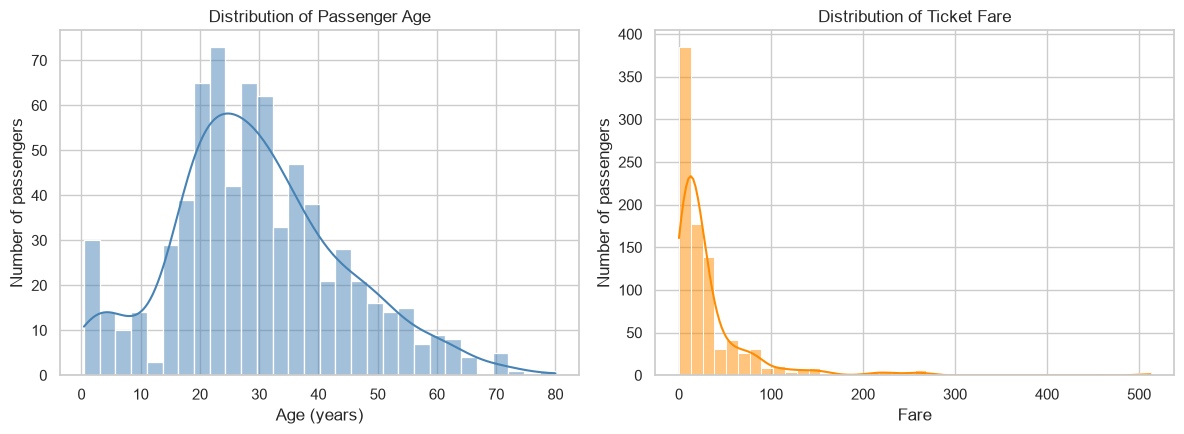

Age skewness: 0.39 | Fare skewness: 4.79
Fare median: 14.4542 | Fare max: 512.3292


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(df["Age"].dropna(), bins=30, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of Passenger Age")
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Number of passengers")
sns.histplot(df["Fare"], bins=40, kde=True, ax=axes[1], color="darkorange")
axes[1].set_title("Distribution of Ticket Fare")
axes[1].set_xlabel("Fare")
axes[1].set_ylabel("Number of passengers")
save_fig("01_age_fare_histograms")
print("Age skewness:", round(df["Age"].skew(), 2), "| Fare skewness:", round(df["Fare"].skew(), 2))
print("Fare median:", df["Fare"].median(), "| Fare max:", df["Fare"].max())

**Observation:** Age is roughly bell shaped with a mild right skew (skewness 0.39); most passengers were between 20 and 40, with a small group of young children. **Fare is strongly right skewed (skewness 4.79)**: the median is 14.45 but a few passengers paid up to 512.33. Logistic regression does not need normally distributed inputs, but the scale difference between Age and Fare is a reason to standardise the features.

### 1.7 Age and Fare by survival outcome

**Purpose:** Box plots compare the distribution of Age and Fare for passengers who survived and who did not. A shift between the two boxes suggests the feature is related to survival.

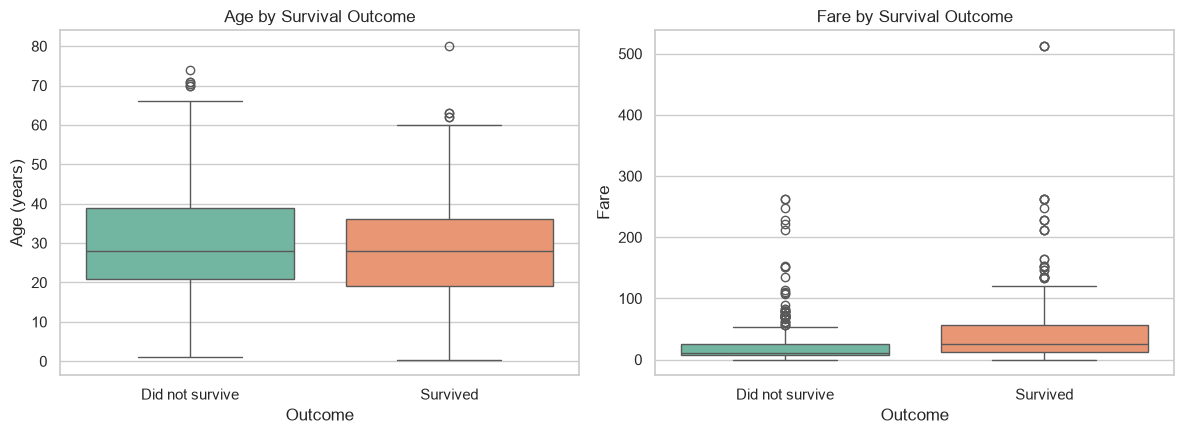

,median_Age,median_Fare
Outcome,,
Did not survive,28.0,10.5
Survived,28.0,26.0


In [10]:
OUTCOMES = ["Did not survive", "Survived"]
plot_df = df.assign(Outcome=df["Survived"].map({0: OUTCOMES[0], 1: OUTCOMES[1]}))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=plot_df, x="Outcome", y="Age", hue="Outcome", order=OUTCOMES, hue_order=OUTCOMES, palette="Set2", legend=False, ax=axes[0])
axes[0].set_title("Age by Survival Outcome")
axes[0].set_xlabel("Outcome")
axes[0].set_ylabel("Age (years)")
sns.boxplot(data=plot_df, x="Outcome", y="Fare", hue="Outcome", order=OUTCOMES, hue_order=OUTCOMES, palette="Set2", legend=False, ax=axes[1])
axes[1].set_title("Fare by Survival Outcome")
axes[1].set_xlabel("Outcome")
axes[1].set_ylabel("Fare")
save_fig("02_age_fare_boxplots")
medians = plot_df.groupby("Outcome")[["Age", "Fare"]].median().rename(columns=lambda c: f"median_{c}")
medians.to_csv(RES_DIR / "median_age_fare_by_outcome.csv")
medians

**Observation:** The median age is **28.0 for both groups**, so age on its own does not separate survivors from non-survivors very well (the model may still use it once sex and class are taken into account). Fare shows a clear shift: **survivors paid a median fare of 26.0 against 10.5 for non-survivors**, which matches the idea that richer passengers had better access to lifeboats.

### 1.8 Survival by Sex and Passenger Class

**Purpose:** Count plots show how many passengers survived or died within each sex and each ticket class.

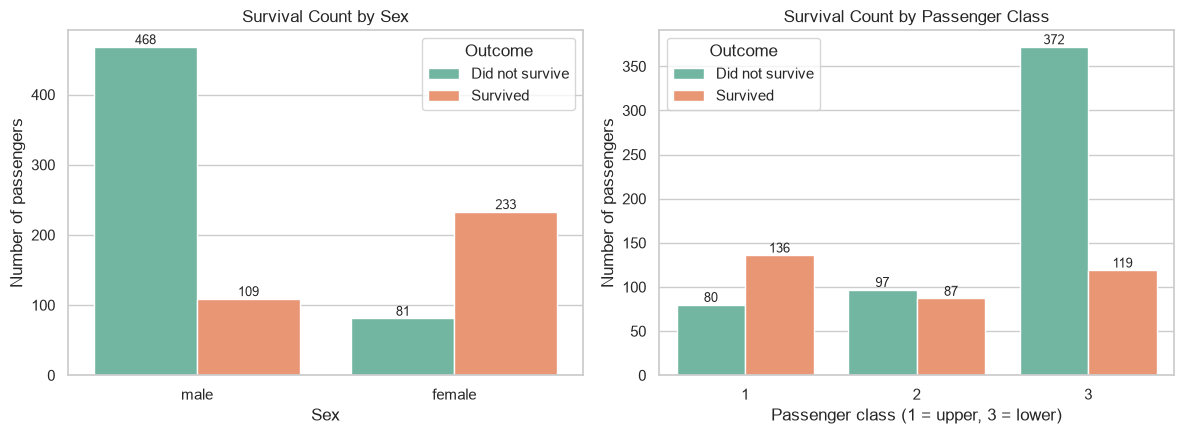

Pclass,1,2,3
Sex,,,
female,0.968,0.921,0.500
male,0.369,0.157,0.135


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.countplot(data=plot_df, x="Sex", hue="Outcome", hue_order=OUTCOMES, palette="Set2", ax=axes[0])
axes[0].set_title("Survival Count by Sex")
axes[0].set_xlabel("Sex")
axes[0].set_ylabel("Number of passengers")
axes[0].legend(title="Outcome")
sns.countplot(data=plot_df, x="Pclass", hue="Outcome", hue_order=OUTCOMES, palette="Set2", ax=axes[1])
axes[1].set_title("Survival Count by Passenger Class")
axes[1].set_xlabel("Passenger class (1 = upper, 3 = lower)")
axes[1].set_ylabel("Number of passengers")
axes[1].legend(title="Outcome")
for ax in axes:
    for c in ax.containers:
        ax.bar_label(c, fontsize=9)
save_fig("03_survival_by_sex_pclass")
sex_class = pd.crosstab(df["Sex"], df["Pclass"], values=df["Survived"], aggfunc="mean").round(3)
sex_class.to_csv(RES_DIR / "survival_rate_sex_by_class.csv")
sex_class

**Observation:** Among males, 468 died and only 109 survived, while among females 233 survived and 81 died. In third class 372 died and 119 survived, whereas in first class 136 survived and 80 died; second class was close to even (87 survived, 97 died). The cross table shows that sex and class combine: **96.8% of first class females survived but only 13.5% of third class males did.** Third class females (50.0%) still did better than first class males (36.9%).

### 1.9 Pair plot of numeric features

**Purpose:** A pair plot shows every pair of numeric features as a scatter plot (and each feature's distribution on the diagonal), coloured by survival. It helps spot relationships between features and how the two classes separate. Rows with missing Age are left out only for this plot.

Rows used in the pair plot: 714


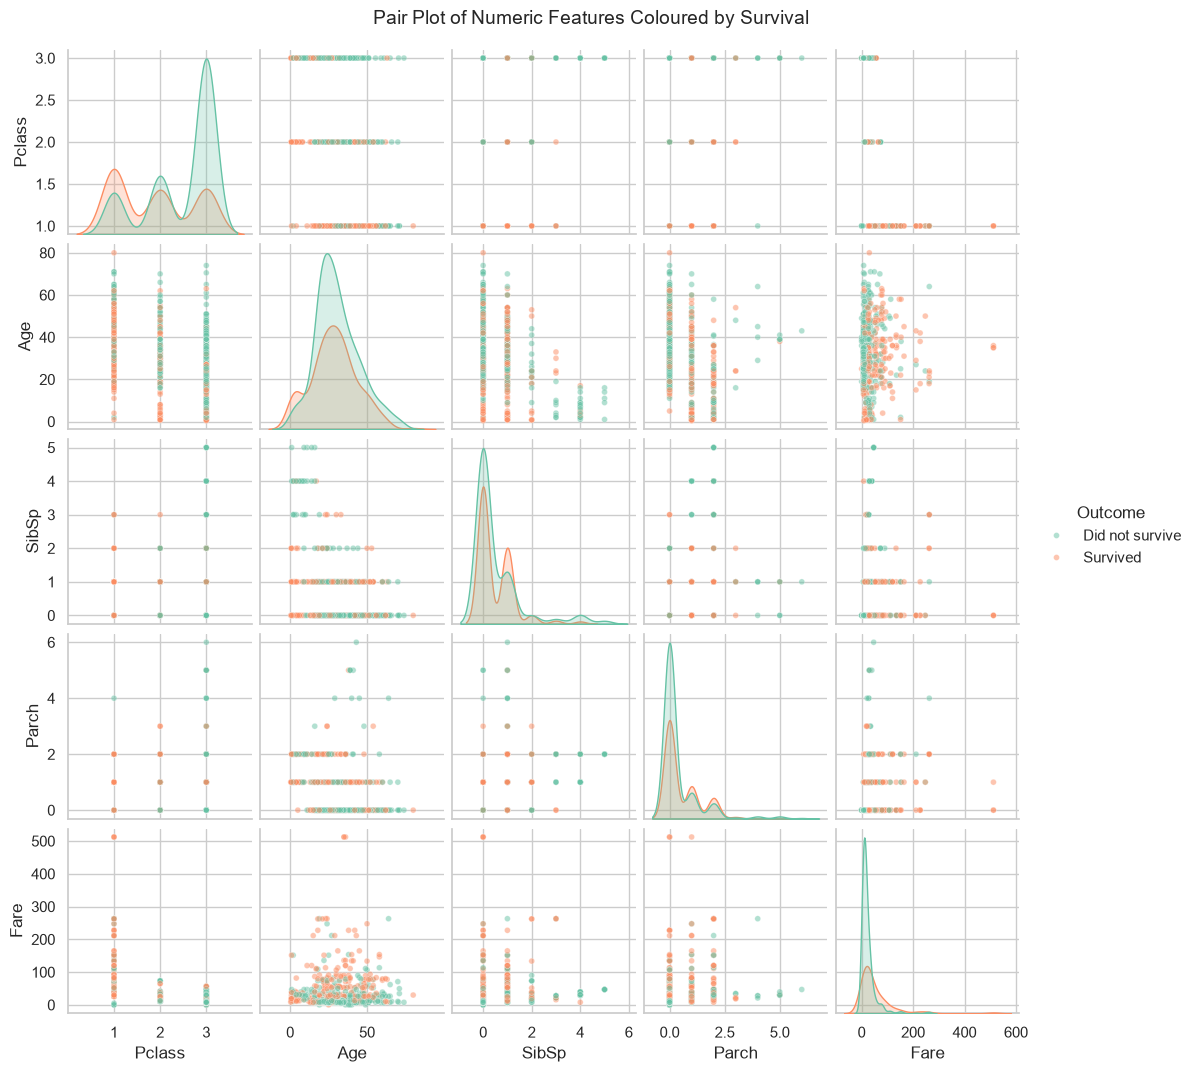

In [12]:
pair_cols = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
pair_df = plot_df[pair_cols + ["Outcome"]].dropna()
print("Rows used in the pair plot:", len(pair_df))
g = sns.pairplot(pair_df, hue="Outcome", hue_order=OUTCOMES, palette="Set2", diag_kind="kde",
                 plot_kws={"alpha": 0.5, "s": 18}, height=2.1)
g.figure.suptitle("Pair Plot of Numeric Features Coloured by Survival", y=1.02, fontsize=14)
g.savefig(FIG_DIR / "04_pairplot.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** The plot uses the 714 passengers with a known Age. Survivors (orange) are concentrated in Pclass 1 and at higher fares, and the third class density on the diagonal is dominated by non-survivors. The Fare vs Pclass panel shows that very high fares appear only in first class, so these two features carry overlapping information. Passengers with large families (SibSp of 3 or more, Parch of 4 or more) are almost all non-survivors. No single pair of numeric features separates the two classes cleanly, which is why a model that combines all features is needed.

### 1.10 Correlation heatmap

**Purpose:** Compute Pearson correlations between the numeric features and the target. Sex is added as a 0/1 column (1 = male) so its relationship with survival is visible on the same scale.

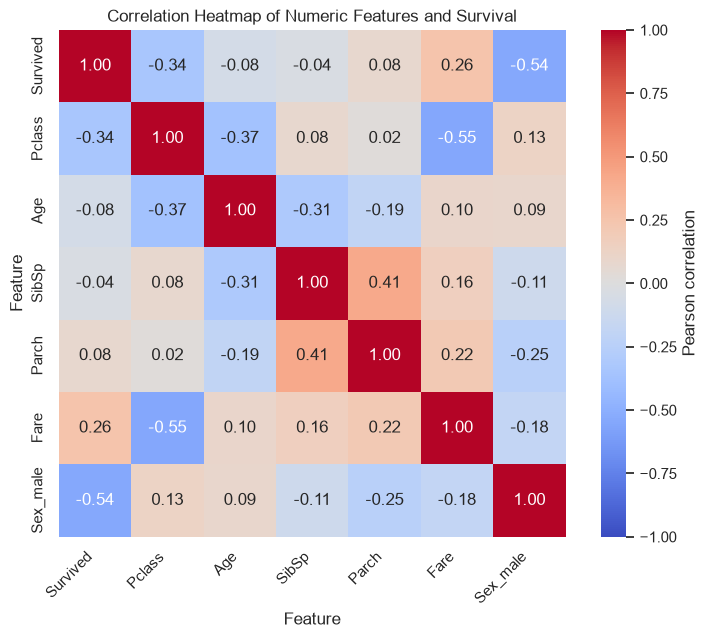

Sex_male   -0.543
Pclass     -0.338
Fare        0.257
Parch       0.082
Age        -0.077
SibSp      -0.035
Name: Survived, dtype: float64

In [13]:
corr_df = df[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]].copy()
corr_df["Sex_male"] = (df["Sex"] == "male").astype(int)
corr = corr_df.corr()
corr.round(3).to_csv(RES_DIR / "correlation_matrix.csv")

plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True,
            cbar_kws={"label": "Pearson correlation"})
plt.title("Correlation Heatmap of Numeric Features and Survival")
plt.xlabel("Feature")
plt.ylabel("Feature")
plt.xticks(rotation=45, ha="right")
save_fig("05_correlation_heatmap")
corr["Survived"].drop("Survived").sort_values(key=abs, ascending=False).round(3)

**Observation:** **Sex_male has the strongest correlation with survival (-0.543)**, followed by Pclass (-0.338) and Fare (+0.257). Age (-0.077), Parch (+0.082) and SibSp (-0.035) have only weak linear relationships with survival. Among the features themselves, **Pclass and Fare are strongly correlated (-0.549)**, Pclass and Age are moderately correlated (-0.369, older passengers tended to be in higher classes) and SibSp and Parch are correlated (+0.415) because both measure family size.

**Observation:** **Summary of the patterns found in the EDA:**

1. Sex is the strongest single factor: females survived at 74.20% against 18.89% for males (correlation -0.543).
2. Social class matters: survival drops from 62.96% in first class to 24.24% in third, and survivors paid a higher median fare (26.0 vs 10.5).
3. Sex and class interact: 96.8% of first class females survived but only 13.5% of third class males.
4. Pclass and Fare overlap (correlation -0.549), so in a model with both, one of them may add little extra information.
5. Age, SibSp and Parch have weak linear correlations with survival, but very large families did badly, and age may matter once sex and class are controlled.
6. Data quality: Cabin is 77.10% missing, Age 19.87% and Embarked 0.22%.

## 2. Data Preprocessing

### 2.1 Choosing features

I drop four columns before modelling:

* **PassengerId**: just a row number, it carries no information about survival.
* **Name**: free text that is unique for every passenger, so it cannot be used directly.
* **Ticket**: an almost unique code with no consistent format.
* **Cabin**: missing for most passengers (see section 1.4), so imputing it would mostly be guessing.

The model uses seven features: Pclass, Sex, Age, SibSp, Parch, Fare and Embarked.

**Purpose:** Separate the predictors (X) from the target (y) and check the class balance of the target.

In [14]:
FEATURES = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
NUMERIC = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
CATEGORICAL = ["Sex", "Embarked"]

X = df[FEATURES]
y = df["Survived"]
print("X shape:", X.shape)
print(y.value_counts().rename(index={0: "Did not survive", 1: "Survived"}))

X shape: (891, 7)
Survived
Did not survive    549
Survived           342
Name: count, dtype: int64


**Observation:** The model input has 891 rows and 7 features. The target has 549 non-survivors and 342 survivors (61.6% vs 38.4%). The classes are moderately imbalanced but not extremely so, so no resampling is needed. It does mean that a model predicting "did not survive" for everyone would already be about 62% accurate, which is the baseline to beat.

### 2.2 Train/test split

**Purpose:** Split the data 80:20 into training and test sets. `stratify=y` keeps the same survival rate in both parts, and `random_state=42` makes the split reproducible. The test set is kept aside until evaluation.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print(f"Survival rate  train: {y_train.mean():.3f} | test: {y_test.mean():.3f}")
print("Missing values in training set:")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

Train: (712, 7) | Test: (179, 7)
Survival rate  train: 0.383 | test: 0.385
Missing values in training set:
Age         137
Embarked      2
dtype: int64


**Observation:** The training set has **712 passengers and the test set 179**. Stratification worked: the survival rate is 0.383 in training and 0.385 in testing, both matching the full data. The training set still has 137 missing Age values and 2 missing Embarked values; these will be filled by the imputers inside the pipeline using training statistics only.

### 2.3 Preprocessing pipeline

All preprocessing is done inside one scikit-learn `Pipeline`, so every step learns its values (medians, most frequent port, means and standard deviations) **only from the training data** and then applies them unchanged to the test data. This avoids data leakage.

* **Numeric columns** (Pclass, Age, SibSp, Parch, Fare): missing values are filled with the training **median** (only Age actually has gaps; the median is used because Age is slightly skewed), then `StandardScaler` puts every column on the same scale (mean 0, standard deviation 1). Scaling makes the coefficients comparable: each one means the effect of a one standard deviation increase.
* **Categorical columns** (Sex, Embarked): missing values are filled with the **most frequent** value (the mode, only Embarked has gaps), then one-hot encoded. I use `drop="first"` so one category becomes the baseline (female for Sex, Cherbourg for Embarked). This avoids perfectly correlated dummy columns, which matters for the statsmodels significance test in section 5.

**Purpose:** Build the ColumnTransformer and the full Pipeline (preprocessing plus logistic regression).

In [16]:
numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, NUMERIC),
    ("cat", categorical_pipe, CATEGORICAL),
])
model = Pipeline([
    ("preprocess", preprocessor),
    ("logreg", LogisticRegression(max_iter=1000)),
])
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('logreg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the 

**Observation:** The diagram confirms the structure: numeric columns go through median imputation then scaling, categorical columns go through most frequent imputation then one-hot encoding (first level dropped), and the transformed data goes into `LogisticRegression(max_iter=1000)`. Because everything is one object, calling `fit` on the training set fits every step on training data only.

## 3. Model Building

**Purpose:** Train the whole pipeline on the training set only. Then look at the values the imputers learned and the transformed feature names.

In [17]:
model.fit(X_train, y_train)

pre = model.named_steps["preprocess"]
age_median = pre.named_transformers_["num"].named_steps["impute"].statistics_[NUMERIC.index("Age")]
embarked_mode = pre.named_transformers_["cat"].named_steps["impute"].statistics_[CATEGORICAL.index("Embarked")]
feature_names = [n.split("__")[1] for n in pre.get_feature_names_out()]
print("Age median learned from training data:", age_median)
print("Embarked mode learned from training data:", embarked_mode)
print("Model input features after preprocessing:", feature_names)
print(f"Training accuracy: {model.score(X_train, y_train):.4f}")

Age median learned from training data: 28.5
Embarked mode learned from training data: S
Model input features after preprocessing: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_Q', 'Embarked_S']
Training accuracy: 0.8076


**Observation:** The imputers learned **an Age median of 28.5 and an Embarked mode of S from the training data only** (the full data median was 28.0, which shows the test set was not used). After preprocessing the model sees 8 inputs: the 5 scaled numeric columns, `Sex_male` (baseline female) and `Embarked_Q`, `Embarked_S` (baseline Cherbourg). The training accuracy is 0.8076.

**Purpose:** Run 5-fold stratified cross-validation on the training set. The pipeline is refit inside every fold, so each fold's validation part is never used for imputation or scaling. Similar scores across folds mean the model is stable and not dependent on one lucky split.

In [18]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
print("Fold accuracies:", np.round(cv_scores, 4))
print(f"Mean CV accuracy: {cv_scores.mean():.4f} (std {cv_scores.std():.4f})")
with open(RES_DIR / "cv_scores.json", "w") as f:
    json.dump({"fold_accuracy": [round(float(s), 4) for s in cv_scores],
               "mean": round(float(cv_scores.mean()), 4),
               "std": round(float(cv_scores.std()), 4)}, f, indent=2)

Fold accuracies: [0.7972 0.7972 0.8028 0.7465 0.831 ]
Mean CV accuracy: 0.7949 (std 0.0273)


**Observation:** The five fold accuracies are 0.7972, 0.7972, 0.8028, 0.7465 and 0.8310, giving a **mean CV accuracy of 0.7949 with a standard deviation of 0.0273**. The scores are fairly consistent (one weaker fold at 0.7465) and the mean is close to the training accuracy of 0.8076, so the model is stable and is not overfitting.

## 4. Model Evaluation

**Purpose:** Predict on the unseen test set and compute accuracy, precision, recall, F1-score and ROC-AUC. The positive class is 1 (Survived). ROC-AUC uses predicted probabilities rather than hard 0/1 labels.

In [19]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred),
    "recall": recall_score(y_test, y_pred),
    "f1": f1_score(y_test, y_pred),
    "roc_auc": roc_auc_score(y_test, y_prob),
}
metrics = {k: round(float(v), 4) for k, v in metrics.items()}
metrics.update({"n_train": int(len(X_train)), "n_test": int(len(X_test)),
                "test_positives": int(y_test.sum()),
                "train_accuracy": round(float(model.score(X_train, y_train)), 4),
                "baseline_accuracy_majority_class": round(float(1 - y_test.mean()), 4)})
with open(RES_DIR / "metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)
pd.Series(metrics, name="value").to_frame()

,value
accuracy,0.8045
precision,0.7931
recall,0.6667
f1,0.7244
roc_auc,0.8435
n_train,712.0000
n_test,179.0000
test_positives,69.0000
train_accuracy,0.8076
baseline_accuracy_majority_class,0.6145


**Observation:** On the 179 unseen test passengers the model scores **accuracy 0.8045, precision 0.7931, recall 0.6667, F1 0.7244 and ROC-AUC 0.8435**. Accuracy is well above the 0.6145 baseline of always predicting "did not survive" and is close to the cross validation mean (0.7949), so the test result is not a lucky split.

**Purpose:** Print the full classification report, which gives precision, recall and F1 for both classes, and save it.

In [20]:
report = classification_report(y_test, y_pred, target_names=["Did not survive", "Survived"], output_dict=True)
pd.DataFrame(report).T.round(4).to_csv(RES_DIR / "classification_report.csv")
print(classification_report(y_test, y_pred, target_names=["Did not survive", "Survived"], digits=4))

                 precision    recall  f1-score   support

Did not survive     0.8099    0.8909    0.8485       110
       Survived     0.7931    0.6667    0.7244        69

       accuracy                         0.8045       179
      macro avg     0.8015    0.7788    0.7864       179
   weighted avg     0.8034    0.8045    0.8007       179



**Observation:** The model is better at recognising non-survivors (recall 0.8909, precision 0.8099, F1 0.8485) than survivors (recall 0.6667, precision 0.7931, F1 0.7244). This is expected because non-survivors are the majority class (110 of 179 in the test set) and the default 0.5 threshold favours them. The weighted average F1 is 0.8007.

**Purpose:** Plot the confusion matrix as a heatmap so the four kinds of outcome (correct and wrong predictions for each class) are easy to read.

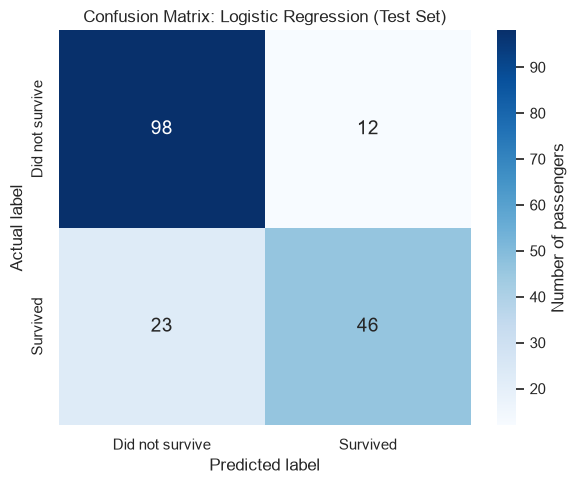

TN=98, FP=12, FN=23, TP=46


In [21]:
cm = confusion_matrix(y_test, y_pred)
labels = ["Did not survive", "Survived"]
pd.DataFrame(cm, index=[f"Actual: {l}" for l in labels],
             columns=[f"Predicted: {l}" for l in labels]).to_csv(RES_DIR / "confusion_matrix.csv")

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels,
            cbar_kws={"label": "Number of passengers"}, annot_kws={"size": 14})
plt.title("Confusion Matrix: Logistic Regression (Test Set)")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
save_fig("06_confusion_matrix")
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

**Observation:** Of the 179 test passengers, 144 were classified correctly (98 true negatives and 46 true positives). The model made **12 false positives** (predicted to survive but actually died) and **23 false negatives** (actually survived but predicted to die). So almost twice as many errors are missed survivors as false alarms, which is why recall (46 of 69 survivors found) is lower than precision (46 of 58 predicted survivors were right).

**Purpose:** Draw the ROC curve, which shows the trade-off between the true positive rate and the false positive rate for every possible probability threshold. The dashed diagonal is what a random guess would give.

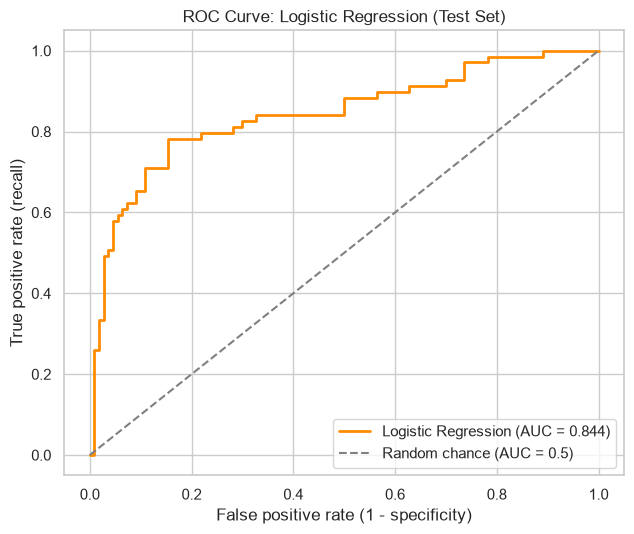

In [22]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
pd.DataFrame({"fpr": fpr, "tpr": tpr, "threshold": thresholds}).to_csv(RES_DIR / "roc_curve.csv", index=False)

plt.figure(figsize=(6.5, 5.5))
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"Logistic Regression (AUC = {metrics['roc_auc']:.3f})")
plt.plot([0, 1], [0, 1], color="grey", lw=1.5, linestyle="--", label="Random chance (AUC = 0.5)")
plt.title("ROC Curve: Logistic Regression (Test Set)")
plt.xlabel("False positive rate (1 - specificity)")
plt.ylabel("True positive rate (recall)")
plt.legend(loc="lower right")
save_fig("07_roc_curve")

**Observation:** The ROC curve stays well above the random chance diagonal over the whole range, rising steeply at low false positive rates. The **AUC of 0.8435** means that if we pick one random survivor and one random non-survivor, the model gives the survivor the higher survival probability about 84% of the time.

**Observation:** **What each metric means for this problem:**

* **Accuracy (0.8045):** 80% of all test passengers were classified correctly. Useful because the classes are only moderately imbalanced, but it hides which class the errors come from.
* **Precision (0.7931):** when the model says "survived", it is right 79% of the time (46 of 58).
* **Recall (0.6667):** the model finds two thirds of the real survivors (46 of 69); the other 23 are missed. This is the weakest metric.
* **F1-score (0.7244):** the harmonic mean of precision and recall, a single score for the survivor class that is low if either of them is low.
* **ROC-AUC (0.8435):** how well the predicted probabilities rank survivors above non-survivors, independent of the 0.5 cut-off. A value of 0.84 shows good separation.

**Errors in practice:** a false negative (23 cases) is a survivor the model wrote off, and a false positive (12 cases) is a passenger the model was too optimistic about. If missing survivors mattered more, the threshold could be lowered below 0.5 to raise recall at the cost of precision.

## 5. Interpretation

### 5.1 Coefficients and odds ratios

**Purpose:** Extract the fitted coefficients, convert them to odds ratios with exp(coef), sort them by size and save the table. Because numeric features were standardised, a numeric coefficient is the change in log-odds of survival for a one standard deviation increase; for a dummy column it is the change compared with the baseline category.

In [23]:
logreg = model.named_steps["logreg"]
num_sd = pd.Series(pre.named_transformers_["num"].named_steps["scale"].scale_, index=NUMERIC)
coef_df = pd.DataFrame({"feature": feature_names, "coefficient": logreg.coef_[0]})
coef_df["odds_ratio"] = np.exp(coef_df["coefficient"])
coef_df["one_unit_means"] = [f"+1 SD ({num_sd[f]:.2f})" if f in NUMERIC else "vs baseline" for f in coef_df["feature"]]
coef_df = coef_df.reindex(coef_df["coefficient"].abs().sort_values(ascending=False).index).reset_index(drop=True)
coef_df[["coefficient", "odds_ratio"]] = coef_df[["coefficient", "odds_ratio"]].round(4)
coef_df.to_csv(RES_DIR / "coefficients.csv", index=False)
print("Intercept:", round(float(logreg.intercept_[0]), 4))
coef_df

Intercept: 1.256


,feature,coefficient,odds_ratio,one_unit_means
0,Sex_male,-2.5598,0.0773,vs baseline
1,Pclass,-0.9158,0.4002,+1 SD (0.83)
2,Age,-0.5009,0.6060,+1 SD (13.02)
3,Embarked_S,-0.3835,0.6815,vs baseline
4,Embarked_Q,0.2885,1.3345,vs baseline
5,SibSp,-0.2577,0.7728,+1 SD (1.06)
6,Fare,0.1017,1.1071,+1 SD (48.03)
7,Parch,-0.0598,0.9419,+1 SD (0.84)


**Observation:** The intercept is 1.256. Reading the coefficients (all others held constant):

* **Sex_male = -2.5598 (odds ratio 0.0773):** being male multiplies the odds of survival by about 0.08 compared with a female, i.e. roughly 92% lower odds. This is by far the largest effect.
* **Pclass = -0.9158 (OR 0.4002):** a one standard deviation increase in class number (0.83, i.e. moving towards third class) cuts the odds of survival by about 60%.
* **Age = -0.5009 (OR 0.6060):** each 13.02 years older (one SD) lowers the odds by about 39%. So age matters once sex and class are controlled, even though the medians in the box plot were equal.
* **Embarked_S = -0.3835 (OR 0.6815)** and **Embarked_Q = +0.2885 (OR 1.3345):** compared with Cherbourg, Southampton passengers had about 32% lower odds and Queenstown about 33% higher odds.
* **SibSp = -0.2577 (OR 0.7728):** more siblings or spouses (per 1.06) lowers the odds by about 23%.
* **Fare = +0.1017 (OR 1.1071)** and **Parch = -0.0598 (OR 0.9419):** small effects. Fare is weak here because most of its information is already captured by Pclass (correlation -0.549).

**Purpose:** Show the coefficients as a horizontal bar chart. Bars to the right raise the chance of survival and bars to the left lower it.

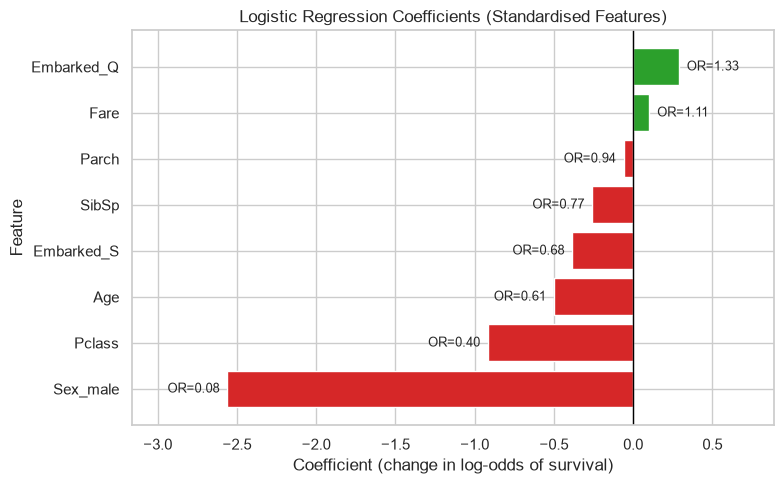

In [24]:
plot_coef = coef_df.sort_values("coefficient")
colors = ["tab:red" if c < 0 else "tab:green" for c in plot_coef["coefficient"]]
plt.figure(figsize=(8, 5))
plt.barh(plot_coef["feature"], plot_coef["coefficient"], color=colors)
plt.axvline(0, color="black", lw=1)
for yv, (c, o) in enumerate(zip(plot_coef["coefficient"], plot_coef["odds_ratio"])):
    plt.text(c + (0.05 if c >= 0 else -0.05), yv, f"OR={o:.2f}", va="center",
             ha="left" if c >= 0 else "right", fontsize=9)
plt.title("Logistic Regression Coefficients (Standardised Features)")
plt.xlabel("Coefficient (change in log-odds of survival)")
plt.ylabel("Feature")
plt.xlim(plot_coef["coefficient"].min() - 0.6, plot_coef["coefficient"].max() + 0.6)
save_fig("08_coefficients")

**Observation:** The chart makes the ranking clear: the Sex_male bar (-2.56) is almost three times longer than the next one, Pclass (-0.92), followed by Age (-0.50). Only Embarked_Q and Fare push towards survival, and both are small. Parch is almost zero.

### 5.2 Statistical significance of the features

**Purpose:** scikit-learn does not give p-values, so I fit a `statsmodels` Logit model on exactly the same preprocessed training data (the pipeline's fitted preprocessor). This gives standard errors, p-values and 95% confidence intervals for each coefficient. Note that scikit-learn's LogisticRegression adds a small L2 penalty by default (C=1), so its coefficients are slightly smaller than the unpenalised statsmodels ones, but the signs and ranking should match.

In [25]:
X_train_proc = pd.DataFrame(pre.transform(X_train), columns=feature_names, index=X_train.index)
logit = sm.Logit(y_train, sm.add_constant(X_train_proc)).fit(disp=0)
print(logit.summary())

                           Logit Regression Results                           
Dep. Variable:               Survived   No. Observations:                  712
Model:                          Logit   Df Residuals:                      703
Method:                           MLE   Df Model:                            8
Date:                Sun, 25 Oct 2026   Pseudo R-squ.:                  0.3449
Time:                        22:56:25   Log-Likelihood:                -310.51
converged:                       True   LL-Null:                       -473.99
Covariance Type:            nonrobust   LLR p-value:                 7.443e-66
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.3315      0.269      4.943      0.000       0.804       1.859
Pclass        -0.9520      0.137     -6.969      0.000      -1.220      -0.684
Age           -0.5186      0.113     -4.596      0.0

**Observation:** The statsmodels model converged with a **pseudo R-squared of 0.3449** and a likelihood ratio test p-value of 7.443e-66, so the features together explain survival far better than an intercept-only model. The unpenalised coefficients are slightly larger than scikit-learn's (for example Sex_male -2.6902 vs -2.5598, Pclass -0.9520 vs -0.9158), as expected from the L2 penalty, but all signs and the ranking of effects are the same.

**Purpose:** Collect the statsmodels results into a tidy table with odds ratios, their 95% confidence intervals and a significance flag at the 0.05 level, and save it.

In [26]:
ci = logit.conf_int()
sig_df = pd.DataFrame({
    "coefficient": logit.params,
    "std_error": logit.bse,
    "z": logit.tvalues,
    "p_value": logit.pvalues,
    "ci_low": ci[0],
    "ci_high": ci[1],
    "odds_ratio": np.exp(logit.params),
    "or_ci_low": np.exp(ci[0]),
    "or_ci_high": np.exp(ci[1]),
})
sig_df["significant_at_0.05"] = np.where(sig_df["p_value"] < 0.05, "Yes", "No")
sig_df.index.name = "feature"
sig_df = sig_df.round(4)
sig_df.to_csv(RES_DIR / "statsmodels_significance.csv")
with open(RES_DIR / "statsmodels_fit.json", "w") as f:
    json.dump({"pseudo_r2": round(float(logit.prsquared), 4), "llr_p_value": float(logit.llr_pvalue),
               "n_obs": int(logit.nobs)}, f, indent=2)
sig_df

,coefficient,std_error,z,p_value,ci_low,ci_high,odds_ratio,or_ci_low,or_ci_high,significant_at_0.05
feature,,,,,,,,,,
const,1.3315,0.2694,4.9433,0.0000,0.8036,1.8594,3.7868,2.2335,6.4202,Yes
Pclass,-0.9520,0.1366,-6.9694,0.0000,-1.2197,-0.6843,0.3860,0.2953,0.5045,Yes
Age,-0.5186,0.1128,-4.5964,0.0000,-0.7398,-0.2975,0.5953,0.4772,0.7427,Yes
SibSp,-0.2688,0.1287,-2.0889,0.0367,-0.5210,-0.0166,0.7643,0.5939,0.9835,Yes
Parch,-0.0706,0.1055,-0.6688,0.5036,-0.2775,0.1363,0.9318,0.7577,1.1460,No
Fare,0.0917,0.1379,0.6655,0.5058,-0.1785,0.3620,1.0961,0.8365,1.4362,No
Sex_male,-2.6902,0.2235,-12.0357,0.0000,-3.1282,-2.2521,0.0679,0.0438,0.1052,Yes
Embarked_Q,0.3192,0.4425,0.7214,0.4706,-0.5481,1.1865,1.3761,0.5781,3.2758,No
Embarked_S,-0.3906,0.2637,-1.4816,0.1384,-0.9074,0.1261,0.6766,0.4036,1.1344,No


**Observation:** At the 0.05 level, **four features are statistically significant: Sex_male, Pclass, Age and SibSp.**

* **Sex_male** (z = -12.04, p < 0.0001): odds ratio 0.068 with 95% CI 0.044 to 0.105, the strongest and most certain effect.
* **Pclass** (p < 0.0001): OR 0.386, CI 0.295 to 0.505.
* **Age** (p < 0.0001): OR 0.595, CI 0.477 to 0.743.
* **SibSp** (p = 0.0367): OR 0.764, CI 0.594 to 0.984. Significant but only just, since the upper limit is close to 1.

**Not significant:** Fare (p = 0.5058), Parch (p = 0.5036), Embarked_Q (p = 0.4706) and Embarked_S (p = 0.1384). Their odds ratio confidence intervals all include 1, meaning "no effect" cannot be ruled out. Fare had a correlation of +0.257 with survival in the EDA, but once Pclass is in the model it adds little, because the two are strongly related. Similarly, the port difference seen in the survival rates largely disappears once sex and class are accounted for.

## 6. Deployment with Streamlit

**Purpose:** Save the complete fitted pipeline (imputers, encoder, scaler and model together) with joblib. Saving the whole pipeline means the app can pass raw inputs straight to it, exactly as in training.

In [27]:
model_path = MODEL_DIR / "titanic_logreg.joblib"
joblib.dump(model, model_path)
print("Saved:", model_path, f"({model_path.stat().st_size / 1024:.1f} KB)")

Saved: model\titanic_logreg.joblib (4.7 KB)


**Observation:** The complete fitted pipeline was saved to `model/titanic_logreg.joblib` (4.7 KB). This single file contains the imputers, encoder, scaler and the logistic regression model.

**Purpose:** Reload the saved file and predict for two example passengers (one of them with Age missing) to check that the saved pipeline works on raw input, including imputation.

In [28]:
loaded = joblib.load(model_path)
examples = pd.DataFrame([
    {"Pclass": 1, "Sex": "female", "Age": 29, "SibSp": 0, "Parch": 0, "Fare": 100.0, "Embarked": "C"},
    {"Pclass": 3, "Sex": "male", "Age": np.nan, "SibSp": 0, "Parch": 0, "Fare": 8.05, "Embarked": "S"},
])
examples["survival_probability"] = loaded.predict_proba(examples[FEATURES])[:, 1].round(4)
examples["predicted_class"] = loaded.predict(examples[FEATURES])
print("Reloaded model gives same test predictions:", bool((loaded.predict(X_test) == y_pred).all()))
examples

Reloaded model gives same test predictions: True


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,survival_probability,predicted_class
0,1,female,29.0,0,0,100.00,C,0.9530,1
1,3,male,NaN,0,0,8.05,S,0.0904,0


**Observation:** The reloaded model gives exactly the same predictions on the test set as the original (`True`). A 29 year old first class female from Cherbourg gets a **survival probability of 0.9530** (predicted: survived), while a third class male from Southampton with Age left blank gets **0.0904** (predicted: did not survive). The second example shows that the saved pipeline fills a missing Age by itself, using the training median of 28.5.

### 6.1 The Streamlit app

The app is in `3/app.py`. It loads the saved pipeline once (cached with `st.cache_resource`, using a path relative to the app file), shows input widgets for the seven features (ports shown by their full names), and when **Predict** is clicked it shows the survival probability and the predicted class.

**Run locally (from the repository root, with the virtual environment activated):**

```
.venv\Scripts\activate
pip install -r requirements.txt
streamlit run 3/app.py
```

The app opens at http://localhost:8501.

**Optional: deploy on Streamlit Community Cloud**

1. Push this repository to GitHub (including `3/app.py`, `3/model/titanic_logreg.joblib` and `requirements.txt` at the repository root).
2. Sign in at https://share.streamlit.io with the GitHub account and click **Create app**.
3. Choose the repository, branch `main`, and set the main file path to `3/app.py`.
4. Click **Deploy**. Streamlit Cloud installs the pinned versions from `requirements.txt`, so the scikit-learn version matches the one used to train the saved model.

## Conclusion

**Observation:** * The Titanic data (891 passengers) showed a clear pattern: females (74.20% survived) and first class passengers (62.96%) had much better chances than males (18.89%) and third class passengers (24.24%).
* After dropping identifier-like and mostly missing columns and handling missing Age and Embarked inside a leak-free Pipeline, a logistic regression model reached **test accuracy 0.8045, precision 0.7931, recall 0.6667, F1 0.7244 and ROC-AUC 0.8435**, with a stable 5-fold CV accuracy of 0.7949 (std 0.0273). This is well above the 0.6145 majority baseline.
* The main weakness is recall: 23 of the 69 test survivors were missed. Lowering the decision threshold would find more survivors at the cost of more false alarms.
* The coefficients and statsmodels p-values agree that **sex, passenger class, age and number of siblings/spouses** are significant predictors (p < 0.05). Being male lowered the odds of survival by about 92%, a lower class and higher age also lowered them, while Fare, Parch and port of embarkation were not significant once these were included.
* The full pipeline was saved and deployed as a Streamlit app (`3/app.py`) that returns a survival probability and class for any passenger details.
* Limitations: the dataset is small (891 rows), Age is 19.87% imputed with a single median value, Cabin information was discarded, and logistic regression assumes linear effects on the log-odds, so interactions such as sex combined with class are only partly captured.

## Attribution

Code structure drafted with AI assistance (Claude); executed, verified and interpreted by Munjampally Manideep. Dataset sources: `titanic.csv` (891 passengers) provided by the course faculty.